In [14]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
%pip install pyarrow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [15]:
df_ch_przeplyw = pd.read_parquet('../data/processed/Chorzów/przeplyw.parquet')
df_ch_scieki = pd.read_parquet('../data/processed/Chorzów/scieki.parquet')
df_ch_awarie = pd.read_parquet('../data/processed/Chorzów/awarie.parquet')
df_ch_energia = pd.read_parquet('../data/processed/Chorzów/energia.parquet')

In [16]:
dfs = {
    "Przepływ": df_ch_przeplyw,
    "Ścieki": df_ch_scieki,
    "Awarie": df_ch_awarie,
    "Energia": df_ch_energia
}

for name, d in dfs.items():
    print(f"=== {name} ===")
    print(f"Wymiary: {d.shape}")
    print(f"Kolumny: {list(d.columns)}")
    print(f"Typy: \n",d.dtypes)
    print(d.head(5))
    print("\n" + "-"*40 + "\n")

=== Przepływ ===
Wymiary: (11215, 4)
Kolumny: ['Data', 'Godzina', 'Przeplyw_chwilowy_cieczy', 'Data_czas']
Typy: 
 Data                                   str
Godzina                                str
Przeplyw_chwilowy_cieczy               str
Data_czas                   datetime64[us]
dtype: object
         Data   Godzina Przeplyw_chwilowy_cieczy           Data_czas
0  11.10.2024  20:34.20                    370,8 2024-10-11 20:34:20
1  12.10.2024  02:10.00                        0 2024-10-12 02:10:00
2  12.10.2024  07:59.38                    367,8 2024-10-12 07:59:38
3  12.10.2024  08:00.26                        0 2024-10-12 08:00:26
4  12.10.2024  13:29.14                    370,6 2024-10-12 13:29:14

----------------------------------------

=== Ścieki ===
Wymiary: (414414, 5)
Kolumny: ['Data', 'Godzina', 'Ilosc_przepompowanych_sciekow', 'Sposób_pomiaru', 'Data_czas']
Typy: 
 Data                                        str
Godzina                                     str
Ilosc_prz

In [17]:
# KONWERSJA DANYCH

# PRZEPŁYW
df_ch_przeplyw['Przeplyw_chwilowy_cieczy'] = (
    df_ch_przeplyw['Przeplyw_chwilowy_cieczy']
    .astype(str)
    .str.replace(',', '.')
)
df_ch_przeplyw['Przeplyw_chwilowy_cieczy'] = pd.to_numeric(df_ch_przeplyw['Przeplyw_chwilowy_cieczy'], errors='coerce')

# ŚCIEKI
df_ch_scieki['Ilosc_przepompowanych_sciekow'] = pd.to_numeric(df_ch_scieki['Ilosc_przepompowanych_sciekow'], errors='coerce')

# ENERGIA

df_ch_energia['Zuzycie_energii_elektrycznej'] = pd.to_numeric(df_ch_energia['Zuzycie_energii_elektrycznej'], errors = 'coerce')

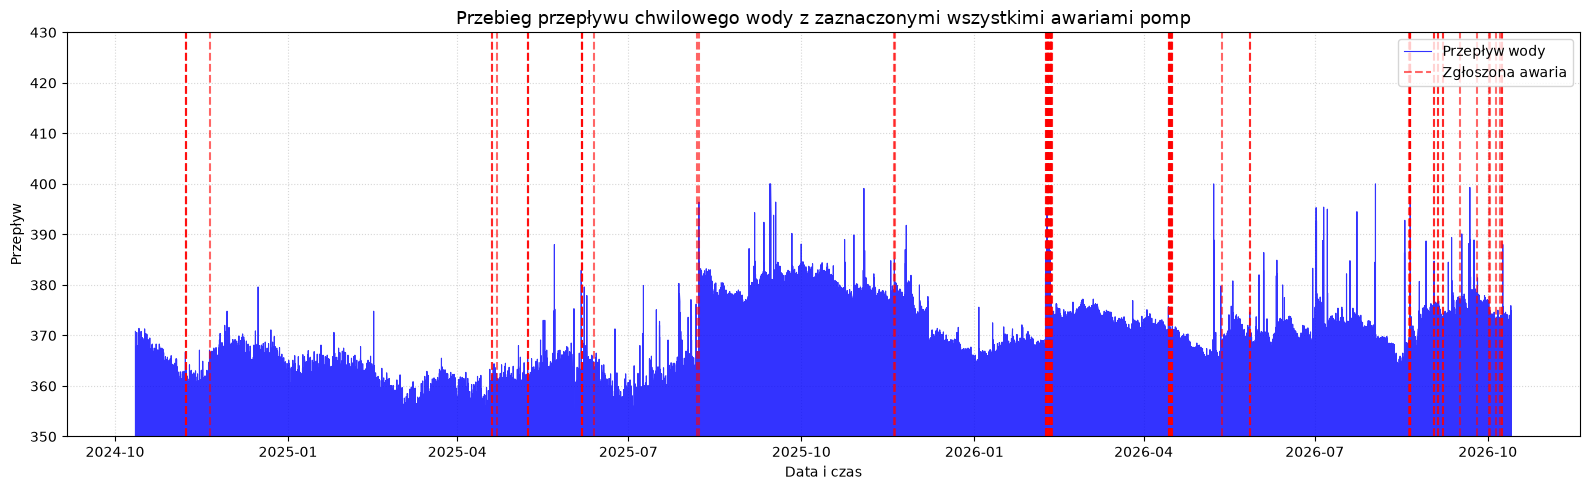

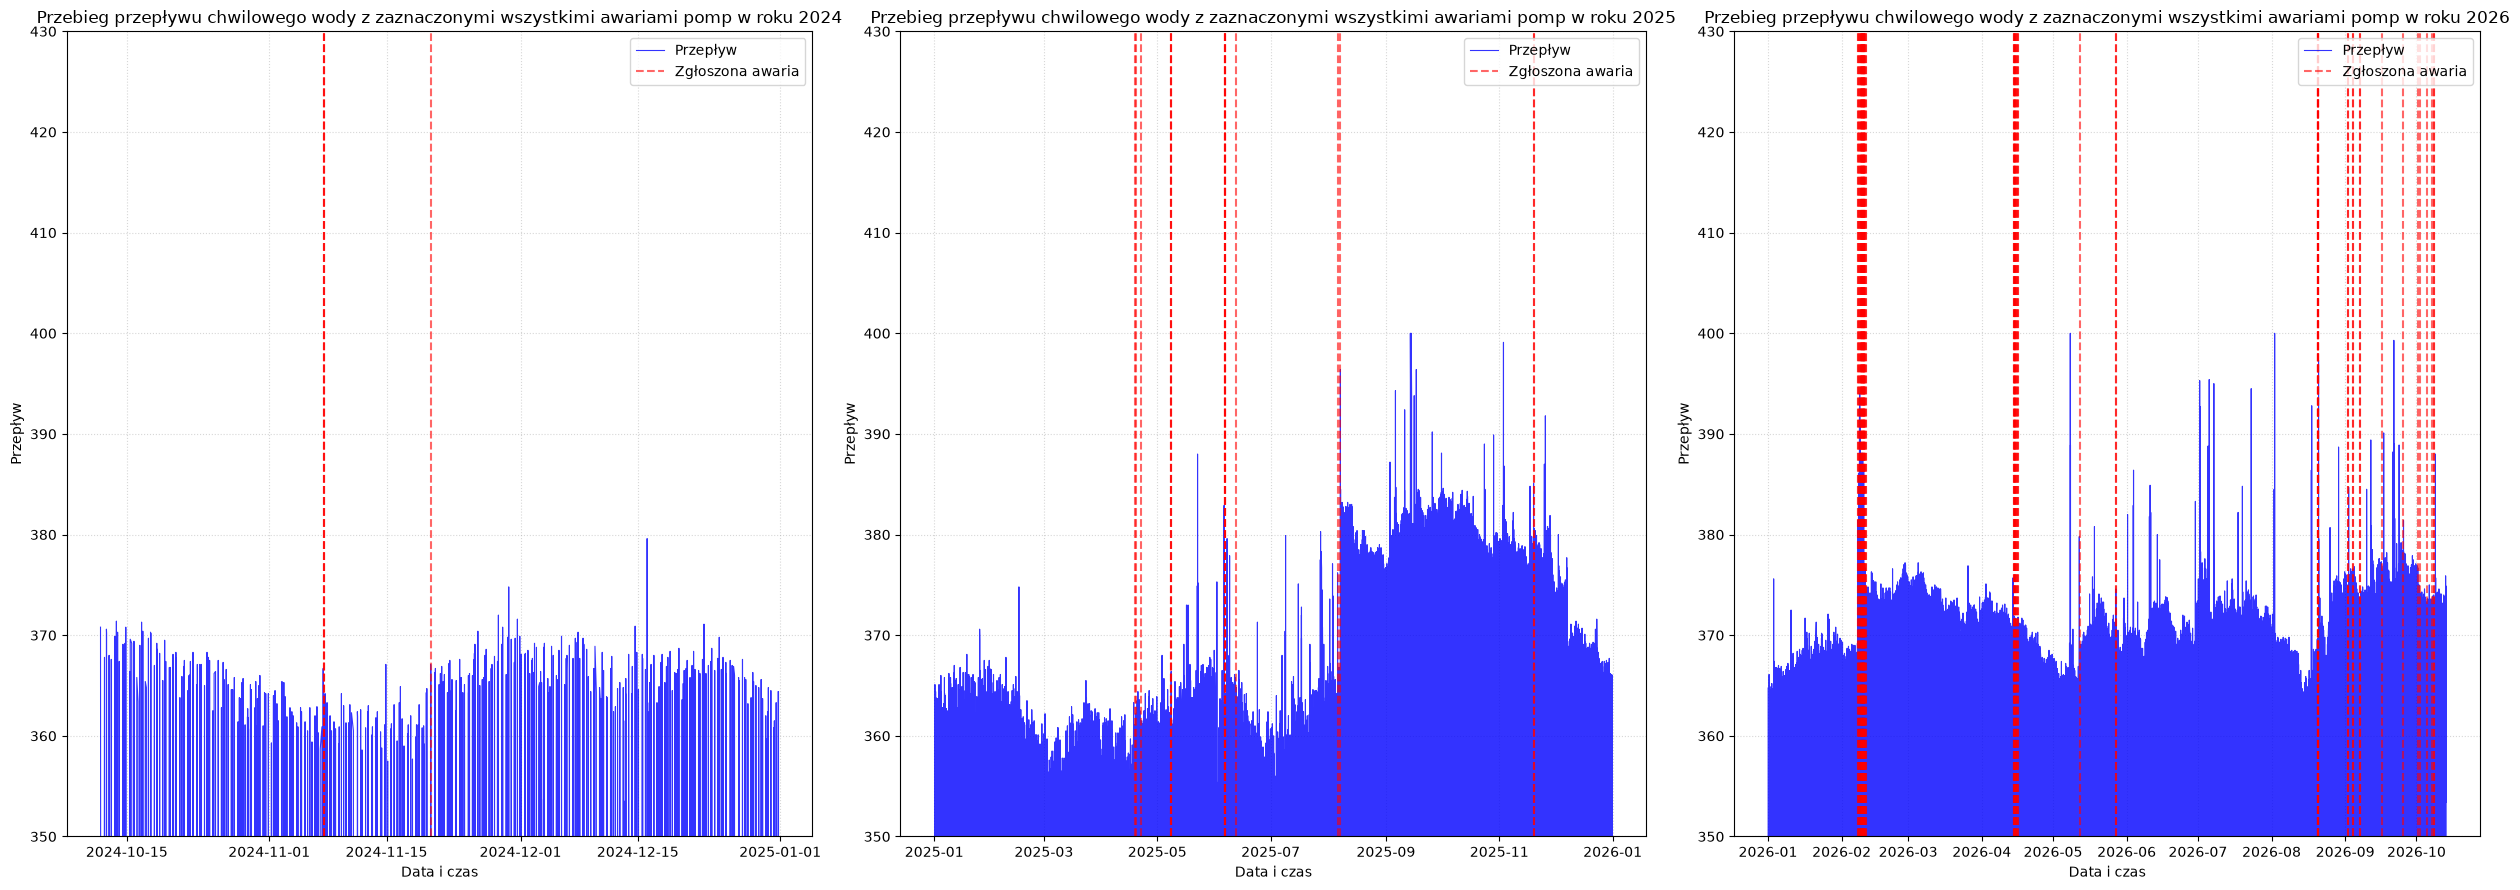

In [18]:
df_p = df_ch_przeplyw.set_index('Data_czas').sort_index()

daty_awarii = df_ch_awarie.loc[(df_ch_awarie['Awaria_pompy_P1'] == '1.00') |
                            (df_ch_awarie['Awaria_pompy_P2'] == '1.00') |
                            (df_ch_awarie['Awaria_pompy_P3'] == '1.00'), 'Data_czas']


fig, ax = plt.subplots(figsize=(16,5))


# Wykres przepływu
ax.plot(df_p.index,df_p['Przeplyw_chwilowy_cieczy'],label = "Przepływ wody", color = "blue", linewidth = 0.8, alpha = 0.8)


for i, data_awarii in enumerate(daty_awarii):
    ax.axvline(
        x=data_awarii,
        color='red',
        linestyle='--',
        alpha=0.6,
        label='Zgłoszona awaria' if i == 0 else ""
    )

ax.set_title('Przebieg przepływu chwilowego wody z zaznaczonymi wszystkimi awariami pomp', fontsize=13)
ax.set_xlabel('Data i czas')
ax.set_ylabel('Przepływ')
ax.set_ylim(350,430)
ax.grid(True, linestyle=':', alpha=0.5)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()


lata = ['2024','2025','2026']


fig2,axes = plt.subplots(1,3,figsize=(25,9))

for ax,rok in zip(axes,lata):
    df_rok = df_p.loc[rok]
    awarie_rok = daty_awarii[daty_awarii.dt.year == int(rok)]

    ax.plot(df_rok.index, df_rok['Przeplyw_chwilowy_cieczy'],label = "Przepływ", color = "blue", linewidth = 0.8, alpha = 0.8)

    for i, awaria in enumerate(awarie_rok):
        ax.axvline(
            x=awaria,
            color='red',
            linestyle='--',
            alpha=0.6,
            label='Zgłoszona awaria' if i == 0 else ""
        )

    ax.set_title(f'Przebieg przepływu chwilowego wody z zaznaczonymi wszystkimi awariami pomp w roku {rok}', fontsize=12)
    ax.set_xlabel('Data i czas')
    ax.set_ylabel('Przepływ')
    ax.set_ylim(350,430)
    ax.grid(True, linestyle=':', alpha=0.5)
    ax.legend(loc='upper right')
plt.tight_layout()
plt.show()